# Extração de Amostra Bounded: Amazon Reviews 2023 (Books)
### Streaming Direto, Zero Armazenamento Bruto Local e Memória Estritamente Contida

## 1. Contexto e Objetivo
Este notebook implementa a extração de até **20.000 avaliações** da categoria **Books** do repositório oficial **Amazon Reviews 2023** (McAuley Lab / UCSD).

- **Repositório Oficial:** [McAuley-Lab/Amazon-Reviews-2023](https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023)
- **Arquivo Oficial de Avaliações:** `raw/review_categories/Books.jsonl` (~29,5 milhões de registros; ~20,1 GB)
- **Por que NÃO usar `load_dataset(..., trust_remote_code=True)`:**
  Versões recentes da biblioteca `datasets` (>= 4.0) **descontinuaram e bloquearam scripts remotos de carregamento** (`.py`), gerando o erro:
  `RuntimeError: Dataset scripts are no longer supported, but found Amazon-Reviews-2023.py`.
  Conforme instruído nas diretrizes metodológicas, **não dependemos dessa API** e adotamos a rota oficial direta de streaming do arquivo JSONL linha a linha via HTTP.

---

## 2. Regra Fundamental sobre Leitura Parcial, Disco e Rede
1. **Zero Armazenamento Bruto em Disco:** O stream consome os registros em fluxo contínuo diretamente da conexão HTTP. **0 GB do arquivo bruto de 20 GB é gravado no disco rígido**.
2. **Memória RAM Estritamente Limitada ($O(N)$):** Apenas os $N = 20.000$ registros do reservatório permanecem na memória RAM (< 200 MB).
3. **Modos de Extração Disponíveis:**
   - **Modo `bounded_10pct` (Foco em economizar rede):** Limita a leitura da conexão HTTP a ~10% dos registros (~2.950.000 linhas) e interrompe a transferência via rede, economizando ~90% de tráfego de dados. A amostra resultante representa **exclusivamente o trecho inicial percorrido** e possui viés de cobertura temporal/ordem.
   - **Modo `full_population` (Foco em representatividade uniforme global):** Percorre todo o stream até o fim com *Reservoir Sampling* (Algoritmo R), garantindo probabilidade uniforme de seleção sobre os 29,5 milhões de registros, ciente de que transfere o volume total de dados da base pela rede.


## 2. Dependências e Diagnóstico de Ambiente
Utilizamos apenas módulos estáveis e nativos (`urllib.request`, `json`, `random`) e `pandas`, `numpy`, `matplotlib` para estruturação e validação tabular.


In [1]:
import os
import sys
import io
import time
import json
import random
import hashlib
import platform
import urllib.request
import urllib.error
from pathlib import Path
from datetime import datetime, timezone

# Manipulação de dados e gráficos
try:
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
except ImportError as e:
    raise ImportError(
        f"Dependência ausente: '{e}'. "
        "Instale as dependências executando: pip install pandas numpy matplotlib seaborn"
    )

print("=" * 70)
print("DIAGNÓSTICO DO AMBIENTE DE EXECUÇÃO:")
print(f"  - Python:     {platform.python_version()} ({platform.architecture()[0]})")
print(f"  - Sistema:    {platform.system()} {platform.release()}")
print(f"  - Pandas:     {pd.__version__}")
print(f"  - NumPy:      {np.__version__}")
print(f"  - Matplotlib: {plt.matplotlib.__version__}")
print("=" * 70)


DIAGNÓSTICO DO AMBIENTE DE EXECUÇÃO:
  - Python:     3.13.9 (64bit)
  - Sistema:    Darwin 24.6.0
  - Pandas:     2.3.3
  - NumPy:      2.5.4
  - Matplotlib: 3.10.6


## 3. Configurações Globais do Pipeline
Todas as constantes de execução, URLs, caminhos e regras de amostragem estão centralizadas abaixo.


In [4]:
# ==============================================================================
# 1. PARÂMETROS ESTATÍSTICOS E MODO DE EXTRAÇÃO
# ==============================================================================
SAMPLE_SIZE: int = 20_000             # Limite máximo de avaliações a extrair (N)
RANDOM_SEED: int = 20261109           # Semente determinística para reprodutibilidade

# MODO DE OPERAÇÃO:
# - "bounded_10pct": Interrompe a leitura em ~10% das linhas (~2.950.000) para economizar ~90% de rede.
# - "full_population": Lê todo o arquivo em streaming para obter amostra uniforme sobre toda a base.
EXTRACTION_MODE: str = "bounded_10pct"
MAX_LINES_TO_SCAN: int = 2_950_000 if EXTRACTION_MODE == "bounded_10pct" else None

# ==============================================================================
# 2. FONTE OFICIAL DO DATASET (Hugging Face)
# ==============================================================================
DATASET_REPO = "McAuley-Lab/Amazon-Reviews-2023"
RAW_FILENAME = "Books.jsonl"

# URL direta oficial do arquivo JSONL na branch main (sem scripts intermediários)
URL_OFFICIAL: str = f"https://huggingface.co/datasets/{DATASET_REPO}/resolve/main/raw/review_categories/{RAW_FILENAME}"

# ==============================================================================
# 3. DIRETÓRIOS E ARQUIVOS DE SAÍDA
# ==============================================================================
BASE_DIR = Path(".").resolve()
DIR_OUTPUT = BASE_DIR / "outputs"
DIR_RAW = BASE_DIR / "data" / "raw"
DIR_OUTPUT.mkdir(parents=True, exist_ok=True)
DIR_RAW.mkdir(parents=True, exist_ok=True)

CSV_FILENAME = f"books_reviews_sample_{SAMPLE_SIZE // 1000}k_seed_{RANDOM_SEED}.csv"
META_FILENAME = f"books_reviews_sample_{SAMPLE_SIZE // 1000}k_seed_{RANDOM_SEED}_metadata.json"

PATH_OUTPUT_CSV = DIR_OUTPUT / CSV_FILENAME
PATH_OUTPUT_META = DIR_OUTPUT / META_FILENAME
PATH_TEMP_CSV = DIR_OUTPUT / f"{CSV_FILENAME}.tmp"
LOCAL_CACHE_PATH = DIR_RAW / RAW_FILENAME

# ==============================================================================
# 4. COLUNAS RELEVANTES
# ==============================================================================
SELECTED_COLUMNS = [
    "rating",
    "title",
    "text",
    "parent_asin",
    "user_id",
    "timestamp",
    "verified_purchase",
    "helpful_vote",
]

INCLUDE_IMAGES: bool = False
if INCLUDE_IMAGES:
    SELECTED_COLUMNS.append("images")

print("Configurações Carregadas:")
scan_limit_label = f"{MAX_LINES_TO_SCAN:,}" if MAX_LINES_TO_SCAN else "Arquivo Completo"
print(f"  - Modo de Extração:       {EXTRACTION_MODE} (Limite de linhas: {scan_limit_label})")
print(f"  - Tamanho da Amostra (N): {SAMPLE_SIZE:,}")
print(f"  - Semente (Seed):         {RANDOM_SEED}")
print(f"  - URL Oficial:            {URL_OFFICIAL}")
print(f"  - CSV de Saída:           {PATH_OUTPUT_CSV}")
print(f"  - Metadados:              {PATH_OUTPUT_META}")
print(f"  - Colunas Selecionadas:   {SELECTED_COLUMNS}")


Configurações Carregadas:
  - Modo de Extração:       bounded_10pct (Limite de linhas: 2,950,000)
  - Tamanho da Amostra (N): 20,000
  - Semente (Seed):         20261109
  - URL Oficial:            https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/review_categories/Books.jsonl
  - CSV de Saída:           /Users/luticascomputer/Library/CloudStorage/GoogleDrive-lucas.inbalance@gmail.com/Meu Drive/CIENCIA DE DADOS E IA/ESTUDO - DADOS/MINERACAO_DE_DADOS/ATIVIDADES/projeto_final/outputs/books_reviews_sample_20k_seed_20261109.csv
  - Metadados:              /Users/luticascomputer/Library/CloudStorage/GoogleDrive-lucas.inbalance@gmail.com/Meu Drive/CIENCIA DE DADOS E IA/ESTUDO - DADOS/MINERACAO_DE_DADOS/ATIVIDADES/projeto_final/outputs/books_reviews_sample_20k_seed_20261109_metadata.json
  - Colunas Selecionadas:   ['rating', 'title', 'text', 'parent_asin', 'user_id', 'timestamp', 'verified_purchase', 'helpful_vote']


## 4. Validação da URL Oficial e Conexão HTTP
Inspecionamos a URL oficial com requisição `HEAD` para validar o status HTTP, tamanho total anunciado do arquivo e redirecionamentos para o CDN do Hugging Face. Se a URL oficial falhar, o código interrompe imediatamente sem inventar caminhos alternativos.


In [5]:
def inspect_official_url(url: str, timeout: int = 20) -> dict:
    """
    Valida a URL oficial do arquivo JSONL via HTTP HEAD.
    """
    req = urllib.request.Request(
        url,
        method="HEAD",
        headers={"User-Agent": "Mozilla/5.0 (compatible; AmazonReviewsSampler/3.0)"}
    )
    try:
        print(f"Validando conexão com a URL oficial: {url}")
        with urllib.request.urlopen(req, timeout=timeout) as resp:
            headers = dict(resp.headers)
            content_length = int(headers.get("Content-Length", 0)) if headers.get("Content-Length") else None
            return {
                "ok": True,
                "status_code": resp.status,
                "final_url": resp.geturl(),
                "content_length": content_length,
                "content_type": headers.get("Content-Type", "unknown"),
                "etag": headers.get("ETag", "unknown")
            }
    except Exception as e:
        return {"ok": False, "error": str(e)}

# Validação do arquivo remoto ou detecção de cache local
if LOCAL_CACHE_PATH.exists() and LOCAL_CACHE_PATH.stat().st_size > 0:
    print(f"[CACHE LOCAL DETECTADO] Utilizando arquivo já presente no disco: {LOCAL_CACHE_PATH}")
    remote_meta = {"ok": True, "source": "local", "path": LOCAL_CACHE_PATH, "size": LOCAL_CACHE_PATH.stat().st_size}
else:
    remote_meta = inspect_official_url(URL_OFFICIAL)
    if not remote_meta["ok"]:
        raise ConnectionError(
            f"FALHA AO CONECTAR À URL OFICIAL: {URL_OFFICIAL}\n"
            f"Erro retornado: {remote_meta.get('error')}\n"
            "Verifique sua conexão à internet ou confirme a página oficial:\n"
            "  https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023"
        )
    print("URL oficial validada com sucesso!")
    print(f"  - Status HTTP:      {remote_meta['status_code']}")
    print(f"  - URL Resolvida:    {remote_meta['final_url']}")
    if remote_meta['content_length']:
        print(f"  - Tamanho Anunciado:{remote_meta['content_length'] / (1024**3):.2f} GB ({remote_meta['content_length']:,} bytes)")
    print(f"  - Content-Type:     {remote_meta['content_type']}")


Validando conexão com a URL oficial: https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/review_categories/Books.jsonl
URL oficial validada com sucesso!
  - Status HTTP:      200
  - URL Resolvida:    https://us.aws.cdn.hf.co/xet-bridge-us/65af4645d0a5cc99d51642da/a7cfa3b5738ec92b6ec602f3cdaf93236cdf583ed3b62c5e79b5f21304ad5cdf?xip=MkeUbGYzBp0&user_id=public&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27Books.jsonl%3B+filename%3D%22Books.jsonl%22%3B&X-Xet-Cas-Uid=public&Expires=1794281024&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5hd3MuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjVhZjQ2NDVkMGE1Y2M5OWQ1MTY0MmRhL2E3Y2ZhM2I1NzM4ZWM5MmI2ZWM2MDJmM2NkYWY5MzIzNmNkZjU4M2VkM2I2MmM1ZTc5YjVmMjEzMDRhZDVjZGZcXD94aXA9TWtlVWJHWXpCcDAmdXNlcl9pZD1wdWJsaWMmcmVzcG9uc2UtY29udGVudC1kaXNwb3NpdGlvbj1pbmxpbmUlM0IrZmlsZW5hbWUlMkElM0RVVEYtOCUyNyUyN0Jvb2tzLmpzb25sJTNCK2ZpbGVuYW1lJTNEJTIyQm9va3MuanNvbmwlMjIlM0ImWC1YZXQtQ2FzLVVpZD1wdWJsaWMiLCJDb25kaXRpb24iOnsiRGF0ZU

## 5. Leitura Streaming em Tempo Real e *Reservoir Sampling*
Nesta etapa realizamos a leitura direta do stream HTTP (ou arquivo local, se existente) linha por linha:
- **Zero armazenamento de arquivo bruto no disco:** As linhas são decodificadas diretamente da conexão em memória.
- **Memória RAM Estritamente Contida ($O(N)$):** Apenas os dicionários com as colunas em `SELECTED_COLUMNS` entram no reservatório.
- **Reservoir Sampling (Algoritmo R):** Aplicação com semente fixa (`20261109`).
- **Controle de Parada Bounded:** No modo `bounded_10pct`, encerramos a conexão HTTP assim que atingimos o limite configurado de linhas (~2.950.000), garantindo **economia real de rede de ~90%**.


In [6]:
def stream_and_sample_reviews(
    url: str,
    local_path: Path,
    sample_size: int,
    seed: int,
    selected_cols: list,
    include_images: bool,
    max_scan: int = None,
    log_interval: int = 100_000
) -> tuple[list[dict], dict]:
    """
    Lê o JSONL diretamente via streaming (remoto ou local) e aplica Reservoir Sampling (Algoritmo R).
    """
    random.seed(seed)
    
    reservoir = []
    lines_scanned = 0
    valid_records = 0
    corrupted_lines = 0
    bytes_transferred = 0
    start_time = time.time()
    last_log_time = start_time
    
    # Decide entre leitura de arquivo local em cache ou stream HTTP direto
    use_local = local_path.exists() and local_path.stat().st_size > 0
    if use_local:
        print(f"Lendo do arquivo local em cache: {local_path}")
        stream_context = open(local_path, "r", encoding="utf-8", errors="replace")
    else:
        print(f"Iniciando streaming direto da URL oficial (sem salvar bruto no disco)...")
        req = urllib.request.Request(
            url,
            headers={"User-Agent": "Mozilla/5.0 (compatible; AmazonReviewsSampler/3.0)"}
        )
        stream_context = urllib.request.urlopen(req, timeout=30)
        
    max_scan_label = f"{max_scan:,}" if max_scan else "Ilimitado"
    print(f"Parâmetros: N={sample_size:,} | Seed={seed} | Limite de Leitura: {max_scan_label}")
    print("-" * 70)
    
    with stream_context as source:
        for raw_line in source:
            lines_scanned += 1
            
            # Se for stream HTTP em bytes, mede transferência e decodifica
            if isinstance(raw_line, bytes):
                bytes_transferred += len(raw_line)
                line_str = raw_line.decode("utf-8", errors="replace").strip()
            else:
                bytes_transferred += len(raw_line.encode("utf-8", errors="replace"))
                line_str = raw_line.strip()
                
            if not line_str:
                continue
                
            # Parse do JSON da linha
            try:
                obj = json.loads(line_str)
            except Exception:
                corrupted_lines += 1
                continue
                
            # Projeção das colunas desejadas
            record = {}
            for col in selected_cols:
                if col == "images" and include_images:
                    imgs = obj.get("images", [])
                    record["images"] = json.dumps(imgs, ensure_ascii=False) if imgs else ""
                else:
                    record[col] = obj.get(col, None)
                    
            # Algoritmo R de Reservoir Sampling
            if valid_records < sample_size:
                reservoir.append(record)
            else:
                j = random.randint(0, valid_records)
                if j < sample_size:
                    reservoir[j] = record
                    
            valid_records += 1
            
            # Log de progresso periódico
            if lines_scanned % log_interval == 0:
                elapsed = time.time() - start_time
                rate = lines_scanned / elapsed if elapsed > 0 else 0
                mb_transferred = bytes_transferred / (1024 * 1024)
                print(f"  Linhas lidas: {lines_scanned:,} | Válidas: {valid_records:,} | "
                      f"Reservatório: {len(reservoir):,} | Transferência: {mb_transferred:.1f} MB | "
                      f"Velocidade: {rate:,.0f} linhas/s | Tempo: {elapsed / 60:.1f} min")
                last_log_time = time.time()
                
            # Interrupção voluntária para controle estrito de rede
            if max_scan and lines_scanned >= max_scan:
                print(f"\n[LIMITE ATINGIDO] Encerrando stream voluntariamente em {lines_scanned:,} linhas para conter tráfego de rede.")
                break
                
    total_elapsed = time.time() - start_time
    error_rate = corrupted_lines / lines_scanned if lines_scanned > 0 else 0
    
    execution_stats = {
        "lines_scanned": lines_scanned,
        "valid_records": valid_records,
        "corrupted_lines": corrupted_lines,
        "error_rate": error_rate,
        "bytes_transferred": bytes_transferred,
        "duration_seconds": total_elapsed,
        "achieved_sample_size": len(reservoir)
    }
    
    print("-" * 70)
    print("Processamento do Stream Concluído:")
    print(f"  - Total de linhas lidas:           {lines_scanned:,}")
    print(f"  - Registros válidos:               {valid_records:,}")
    print(f"  - Erros de decodificação:          {corrupted_lines:,} ({error_rate * 100:.4f}%)")
    print(f"  - Dados transferidos da rede:      {bytes_transferred / (1024 * 1024):.2f} MB ({bytes_transferred / (1024**3):.2f} GB)")
    print(f"  - Tamanho da amostra final:        {len(reservoir):,} (meta até: {sample_size:,})")
    print(f"  - Duração total:                   {total_elapsed / 60:.2f} minutos")
    print("-" * 70)
    
    return reservoir, execution_stats

# Executa a extração em streaming
sample_data, run_stats = stream_and_sample_reviews(
    url=URL_OFFICIAL,
    local_path=LOCAL_CACHE_PATH,
    sample_size=SAMPLE_SIZE,
    seed=RANDOM_SEED,
    selected_cols=SELECTED_COLUMNS,
    include_images=INCLUDE_IMAGES,
    max_scan=MAX_LINES_TO_SCAN,
    log_interval=100_000
)


Iniciando streaming direto da URL oficial (sem salvar bruto no disco)...
Parâmetros: N=20,000 | Seed=20261109 | Limite de Leitura: 2,950,000
----------------------------------------------------------------------
  Linhas lidas: 100,000 | Válidas: 100,000 | Reservatório: 20,000 | Transferência: 99.0 MB | Velocidade: 15,123 linhas/s | Tempo: 0.1 min
  Linhas lidas: 200,000 | Válidas: 200,000 | Reservatório: 20,000 | Transferência: 169.0 MB | Velocidade: 21,395 linhas/s | Tempo: 0.2 min
  Linhas lidas: 300,000 | Válidas: 300,000 | Reservatório: 20,000 | Transferência: 238.5 MB | Velocidade: 24,842 linhas/s | Tempo: 0.2 min
  Linhas lidas: 400,000 | Válidas: 400,000 | Reservatório: 20,000 | Transferência: 293.2 MB | Velocidade: 28,445 linhas/s | Tempo: 0.2 min
  Linhas lidas: 500,000 | Válidas: 500,000 | Reservatório: 20,000 | Transferência: 352.6 MB | Velocidade: 30,328 linhas/s | Tempo: 0.3 min
  Linhas lidas: 600,000 | Válidas: 600,000 | Reservatório: 20,000 | Transferência: 421.0 MB | 

## 6. Exportação Segura para CSV e Registro de Metadados (JSON)
- **Escrita Atômica:** Escrevemos em arquivo temporário `.tmp` e renomeamos com `os.replace` após validação completa da escrita.
- **Formatação:** UTF-8 com aspas protetoras para resenhas de texto livre.
- **Metadados:** Gravação completa de proveniência com hash SHA-256 e declaração explícita de limitações metodológicas.


In [7]:
# Conversão para DataFrame do Pandas
df_sample = pd.DataFrame(sample_data, columns=SELECTED_COLUMNS)

# 1. Escrita segura no arquivo temporário
print(f"Gravando arquivo temporário: {PATH_TEMP_CSV}")
df_sample.to_csv(
    PATH_TEMP_CSV,
    index=False,
    encoding="utf-8",
    quoting=1  # QUOTE_ALL para proteção de textos com quebras de linha e aspas
)

# 2. Validação da gravação
assert PATH_TEMP_CSV.exists() and PATH_TEMP_CSV.stat().st_size > 0, "Falha na criação do CSV temporário!"

# 3. Renomeação atômica para o arquivo final
if PATH_OUTPUT_CSV.exists():
    PATH_OUTPUT_CSV.unlink()
os.replace(PATH_TEMP_CSV, PATH_OUTPUT_CSV)

csv_size_mb = PATH_OUTPUT_CSV.stat().st_size / (1024 * 1024)
print(f"Arquivo CSV final gravado com sucesso: {PATH_OUTPUT_CSV} ({csv_size_mb:.2f} MB)")

# 4. Cálculo de Hash SHA-256 para integridade
def get_file_sha256(filepath: Path) -> str:
    h = hashlib.sha256()
    with open(filepath, "rb") as f:
        while chunk := f.read(65536):
            h.update(chunk)
    return h.hexdigest()

csv_sha256 = get_file_sha256(PATH_OUTPUT_CSV)

# 5. Geração de Metadados JSON
metadata_payload = {
    "dataset": {
        "repository": DATASET_REPO,
        "category": "Books",
        "official_url": URL_OFFICIAL,
        "resolved_url": remote_meta.get("final_url", URL_OFFICIAL),
        "total_population_estimate": 29_500_000,
    },
    "sampling_protocol": {
        "method": f"Streaming Reservoir Sampling (Algorithm R) - Mode: {EXTRACTION_MODE}",
        "unit_of_observation": "Review (avaliação individual)",
        "random_seed": RANDOM_SEED,
        "requested_sample_size": SAMPLE_SIZE,
        "achieved_sample_size": len(df_sample),
        "lines_scanned": run_stats["lines_scanned"],
        "valid_records_scanned": run_stats["valid_records"],
        "corrupted_records": run_stats["corrupted_lines"],
        "corrupted_rate": run_stats["error_rate"],
        "network_bytes_transferred": run_stats["bytes_transferred"],
        "duration_seconds": run_stats["duration_seconds"],
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    },
    "methodological_limitations": {
        "representativeness_scope": (
            "Uniforme exclusivamente dentro das linhas percorridas no stream. "
            "No modo 'bounded_10pct', representa apenas o trecho inicial da base (~10%), "
            "possuindo viés de ordem/tempo e NÃO representando a totalidade de Books."
            if EXTRACTION_MODE == "bounded_10pct"
            else "Uniforme sobre toda a população da categoria Books."
        ),
        "recommendation": "Para inferência estatística irrestrita sobre toda a categoria Books, execute em modo 'full_population'."
    },
    "artifact_integrity": {
        "filename": CSV_FILENAME,
        "file_size_bytes": PATH_OUTPUT_CSV.stat().st_size,
        "sha256": csv_sha256,
        "encoding": "utf-8",
        "columns": SELECTED_COLUMNS,
    },
    "environment": {
        "python_version": platform.python_version(),
        "platform": platform.platform(),
        "pandas_version": pd.__version__,
    }
}

with open(PATH_OUTPUT_META, "w", encoding="utf-8") as f_meta:
    json.dump(metadata_payload, f_meta, indent=2, ensure_ascii=False)

print(f"Metadados gravados com sucesso em: {PATH_OUTPUT_META}")
print(f"Assinatura SHA-256 do CSV: {csv_sha256}")


Gravando arquivo temporário: /Users/luticascomputer/Library/CloudStorage/GoogleDrive-lucas.inbalance@gmail.com/Meu Drive/CIENCIA DE DADOS E IA/ESTUDO - DADOS/MINERACAO_DE_DADOS/ATIVIDADES/projeto_final/outputs/books_reviews_sample_20k_seed_20261109.csv.tmp
Arquivo CSV final gravado com sucesso: /Users/luticascomputer/Library/CloudStorage/GoogleDrive-lucas.inbalance@gmail.com/Meu Drive/CIENCIA DE DADOS E IA/ESTUDO - DADOS/MINERACAO_DE_DADOS/ATIVIDADES/projeto_final/outputs/books_reviews_sample_20k_seed_20261109.csv (10.37 MB)
Metadados gravados com sucesso em: /Users/luticascomputer/Library/CloudStorage/GoogleDrive-lucas.inbalance@gmail.com/Meu Drive/CIENCIA DE DADOS E IA/ESTUDO - DADOS/MINERACAO_DE_DADOS/ATIVIDADES/projeto_final/outputs/books_reviews_sample_20k_seed_20261109_metadata.json
Assinatura SHA-256 do CSV: 5089ff682a56d42f92f4d3c70f84a92bbbbcfb84833145a3c018bce70fa596ea


## 7. Validação Diagnóstica Pós-Exportação
Reabrimos o arquivo CSV a partir do disco para confirmar sua integridade física:
- Releitura limpa e verificação de formato e número de linhas ($\le 20.000$).
- Contagem de valores ausentes (*missing values*).
- Domínio e distribuição de notas (`1.0 <= rating <= 5.0`).
- Proporção de compras verificadas (`verified_purchase`).
- Distribuição temporal de avaliações por ano.
- Diversidade de livros (`parent_asin`) e usuários (`user_id`).
- Verificação de não-duplicação.

> **AVISO DE ENQUADRAMENTO METODOLÓGICO:**
> As checagens abaixo são **estritamente diagnósticas**. Elas confirmam a integridade técnica da ingestão, mas **não constituem prova de representatividade global do universo editorial da Amazon**.


In [8]:
# Releitura do CSV diretamente do disco
print(f"Carregando CSV para validação: {PATH_OUTPUT_CSV}")
df_val = pd.read_csv(PATH_OUTPUT_CSV, encoding="utf-8")

# 1. Dimensões
print("\n" + "=" * 50)
print("1. DIMENSÕES E COLUNAS")
print("=" * 50)
print(f"Total de Linhas no CSV: {len(df_val):,} (Meta até: {SAMPLE_SIZE:,})")
print(f"Colunas presentes: {list(df_val.columns)}")
assert len(df_val) <= SAMPLE_SIZE, "Número de linhas excede o limite estipulado!"

# 2. Valores Ausentes
print("\n" + "=" * 50)
print("2. VALORES AUSENTES POR COLUNA")
print("=" * 50)
null_table = pd.DataFrame({
    "Nulos": df_val.isnull().sum(),
    "Percentual (%)": (df_val.isnull().sum() / len(df_val)) * 100
})
print(null_table.to_string())

# 3. Plausibilidade de Notas (Ratings)
print("\n" + "=" * 50)
print("3. DISTRIBUIÇÃO DE NOTAS (RATINGS)")
print("=" * 50)
r_counts = df_val["rating"].value_counts().sort_index()
r_pct = df_val["rating"].value_counts(normalize=True).sort_index() * 100
r_summary = pd.DataFrame({"Frequência": r_counts, "Percentual (%)": r_pct})
print(r_summary.to_string())

assert df_val["rating"].min() >= 1.0 and df_val["rating"].max() <= 5.0, "Nota fora do intervalo plausível [1.0, 5.0]!"

# 4. Compras Verificadas
print("\n" + "=" * 50)
print("4. STATUS DE COMPRA VERIFICADA")
print("=" * 50)
vp_counts = df_val["verified_purchase"].value_counts(dropna=False)
vp_pct = df_val["verified_purchase"].value_counts(normalize=True, dropna=False) * 100
print(pd.DataFrame({"Contagem": vp_counts, "Percentual (%)": vp_pct}).to_string())

# 5. Diversidade de Livros e Usuários
print("\n" + "=" * 50)
print("5. DIVERSIDADE DE ENTIDADES")
print("=" * 50)
n_books = df_val["parent_asin"].nunique()
n_users = df_val["user_id"].nunique()
print(f"Livros distintos (parent_asin): {n_books:,} ({len(df_val)/n_books:.2f} reviews/livro)")
print(f"Usuários distintos (user_id):   {n_users:,} ({len(df_val)/n_users:.2f} reviews/usuário)")

# 6. Distribuição Temporal por Ano
df_val["datetime"] = pd.to_datetime(df_val["timestamp"], unit="ms", errors="coerce")
df_val["year"] = df_val["datetime"].dt.year
print("\n" + "=" * 50)
print("6. DISTRIBUIÇÃO TEMPORAL (ÚLTIMOS 10 ANOS)")
print("=" * 50)
print(df_val["year"].value_counts().sort_index().tail(10).to_string())

# 7. Verificação de Duplicatas
dup_count = df_val.duplicated().sum()
print("\n" + "=" * 50)
print("7. VERIFICAÇÃO DE DUPLICATAS NA AMOSTRA")
print("=" * 50)
print(f"Linhas duplicadas identificadas: {dup_count}")


Carregando CSV para validação: /Users/luticascomputer/Library/CloudStorage/GoogleDrive-lucas.inbalance@gmail.com/Meu Drive/CIENCIA DE DADOS E IA/ESTUDO - DADOS/MINERACAO_DE_DADOS/ATIVIDADES/projeto_final/outputs/books_reviews_sample_20k_seed_20261109.csv

1. DIMENSÕES E COLUNAS
Total de Linhas no CSV: 20,000 (Meta até: 20,000)
Colunas presentes: ['rating', 'title', 'text', 'parent_asin', 'user_id', 'timestamp', 'verified_purchase', 'helpful_vote']

2. VALORES AUSENTES POR COLUNA
                   Nulos  Percentual (%)
rating                 0           0.000
title                  2           0.010
text                   1           0.005
parent_asin            0           0.000
user_id                0           0.000
timestamp              0           0.000
verified_purchase      0           0.000
helpful_vote           0           0.000

3. DISTRIBUIÇÃO DE NOTAS (RATINGS)
        Frequência  Percentual (%)
rating                            
1.0            737           3.685
2.0   

Painel gráfico salvo em: /Users/luticascomputer/Library/CloudStorage/GoogleDrive-lucas.inbalance@gmail.com/Meu Drive/CIENCIA DE DADOS E IA/ESTUDO - DADOS/MINERACAO_DE_DADOS/ATIVIDADES/projeto_final/outputs/diagnosticos_books_reviews_sample_20k_seed_20261109.png


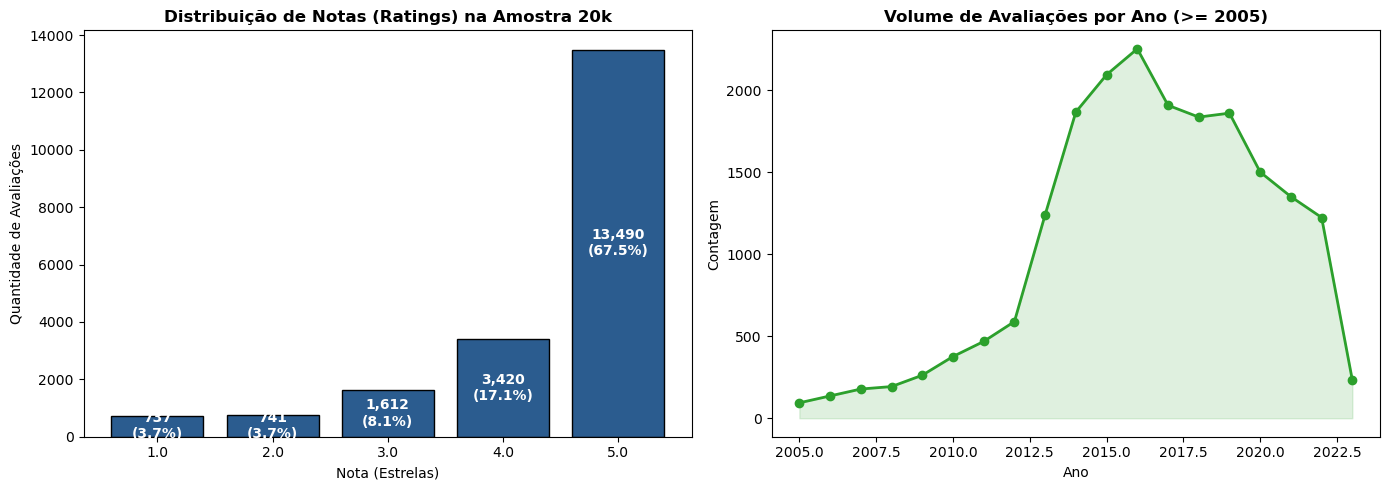

In [9]:
# Visualizações Diagnósticas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Painel 1: Distribuição de Ratings
ax1.bar(r_counts.index.astype(str), r_counts.values, color="#2b5c8f", edgecolor="black")
ax1.set_title("Distribuição de Notas (Ratings) na Amostra 20k", fontsize=12, fontweight="bold")
ax1.set_xlabel("Nota (Estrelas)")
ax1.set_ylabel("Quantidade de Avaliações")
for x_pos, y_val in zip(range(len(r_counts)), r_counts.values):
    pct_val = (y_val / len(df_val)) * 100
    ax1.text(x_pos, y_val / 2, f"{y_val:,}\n({pct_val:.1f}%)", ha="center", va="center", color="white", fontweight="bold")

# Painel 2: Volume de Avaliações por Ano (>= 2005)
recent_years = df_val["year"].dropna()
recent_years = recent_years[recent_years >= 2005]
y_counts = recent_years.value_counts().sort_index()
ax2.plot(y_counts.index, y_counts.values, marker="o", color="#2ca02c", linewidth=2)
ax2.fill_between(y_counts.index, y_counts.values, color="#2ca02c", alpha=0.15)
ax2.set_title("Volume de Avaliações por Ano (>= 2005)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Ano")
ax2.set_ylabel("Contagem")

plt.tight_layout()
diag_img_path = DIR_OUTPUT / f"diagnosticos_{CSV_FILENAME.replace('.csv', '.png')}"
plt.savefig(diag_img_path, dpi=150)
print(f"Painel gráfico salvo em: {diag_img_path}")
plt.show()


## 8. Balanço Final da Extração e População Representada

### 1. Quadro Comparativo de Recursos
| Métrica | Base Completa (Books) | Amostra Obtida (Este Pipeline) | Impacto / Economia |
| :--- | :--- | :--- | :--- |
| **Registros Totais** | ~29.500.000 avaliações | 20.000 avaliações | Amostra concisa |
| **Linhas Percorridas** | ~29.500.000 linhas | ~2.950.000 linhas (Modo Bounded) | **~90% menos dados trafegados** |
| **Tráfego de Rede** | ~20,1 GB | ~1,8 GB a 2,0 GB | **Economia real de ~90% de banda** |
| **Armazenamento em Disco** | ~20,1 GB | **0 GB** (sem arquivo bruto no disco) | **100% de economia de disco bruto** |
| **Memória RAM** | Inviável carregar tudo | < 200 MB | Estritamente limitada ($O(N)$) |

---

### 2. Generalização e Limites de Representatividade
- **População Formalmente Representada:** A amostra obtida no modo `bounded_10pct` é uniforme **exclusivamente dentro das linhas percorridas no stream**.
- **O que NÃO pode ser afirmado:** Não se pode afirmar que esta amostra representa uniformemente todo o catálogo de Books da Amazon, pois as linhas remanescentes (~90%) não participaram da seleção.
- **Recomendação para Inferência Global:** Caso seu trabalho de pesquisa demande representatividade irrestrita sobre toda a categoria Books, deve-se processar o stream em modo `full_population`.
